# Finding the 12x12 Williamson-type Hadamard Matrix using NN-assisted QAOA

#### **Abstract**
In this notebook, we explore the application of Quantum Approximate Optimization Algorithm (QAOA) to find a 12x12 Williamson-type Hadamard matrix. We will leverage a `neural network (NN)` to assist in optimizing the parameters of the QAOA circuit, aiming to minimize the expected cost and maximize the success probability of obtaining a valid solution.

In the previous $12\times 12$ Williamson-type Hadamard matrix notebook, we used `classical optimization algorithms` like `COBYLA` and `Nelder-Mead` to optimize the parameters of the QAOA circuit. However, these methods can be computationally expensive and may not always converge to the optimal solution.

For example, COBYLA starts with an initial guess $\theta_0=(0.5, 0.5)$ and iteratively updates the parameters to minimize the QAOA objective function until it finds promising parameters.

In the previous notebook, the workflow was as follows:
$$\text{Classical Optimization/Initial Parameters ($\beta$, $\gamma$)}\\ \downarrow \\
\text{COBYLA/Nelder-Mead Optimization}\\ \downarrow \\
\text{QAOA Circuit/Parameters and measurements}\\ \downarrow \\
\text{Expected Cost and Success Probability}\\ \downarrow \\
\text{Hadamard Matrix}$$

The optimizer repeatedly updates the parameters $\beta$, $\gamma$. 

In this notebook, we will introduce a `neural network` to assist in the optimization process.

The workflow in this notebook will be as follows:
$$\text{Problem Information}\\ \downarrow \\
\text{Neural Network Training}\\ \downarrow \\
\text{Predicted Parameters ($\beta$, $\gamma$)}\\ \downarrow \\
\text{QAOA Circuit/Parameters and measurements}\\ \downarrow \\
\text{Expected Cost and Success Probability}\\ \downarrow \\
\text{Hadamard Matrix}$$

The `NN` would learn to predict the promising QAOA parameters ($\beta$, $\gamma$), potentially reducing the number of iterations, number of expensive objective evaluations. We would train it using data from multiple QAOA optimization runs. 

Importantly, the `NN` training also requires classical computation. Our research question is whether offline training of the `NN` can provide a significant speedup and can reduce the repeated parameter-search cost when solving new instances of the problem.

$$\boxed{\text{NN: Problem Information } \rightarrow \text{ Predicted Parameters $(\beta_{\text{pred}}, \gamma_{\text{pred}})$}}$$

Instead of starting COBYLA with a random initial guess, we give it the NN-predicted parameters $(\beta_{\text{pred}}, \gamma_{\text{pred}})$ as the initial guess. The hope is that the NN can provide a better starting point for the optimization, leading to faster convergence and better solutions.

---
> **Research Question**: Can a trained neural network predict promising QAOA parameters and reduce the number of classical optimization evaluations required to achieve a target success probability ( i.e., `for finding a 12x12 Williamson-type Hadamard matrix`)?
___

We can begin with a simple feedforward neural network architecture: 

$$\boxed{\text{Input Layer} \rightarrow \text{Hidden Layer} \rightarrow \text{Output Layer}}$$

$$\boxed{\beta_0, \gamma_0, \\ \text{problem features} \rightarrow \text{Dense Layer: 32 neurons(ReLU activation)}\rightarrow \\ \text{Dense Layer: 16 neurons(ReLU activation)}\rightarrow \text{Output Layer: $\beta_{pred}, \gamma_{pred}$}}$$

This is a proposed starting architecture, not an architecture we have experimentally validated. We can experiment with different architectures, activation functions, and hyperparameters to find the best performing model for our specific problem.

### **How will the NN be trained?**
This is a crucial part of the workflow. The NN cannot magically know the optimal QAOA parameters. We must first generate a training data. 

To `generate training data`, we can run the `COBYLA` multiple times, using different initial parameter values. 

For example 

| Run | Initial $\gamma$ | Initial $\beta$ | Optimized $\gamma$ | Optimized $\beta$ |
|-----|------------------|-----------------|--------------------|-------------------|
| 1   | 0.05             | 0.05            | From COBYLA        | From COBYLA       |
| 2   | 0.10             | 0.20            | From COBYLA        | From COBYLA       |
| 3   | 0.30             | 0.15            | From COBYLA        | From COBYLA       |
| 4   | 0.40             | 0.35            | From COBYLA        | From COBYLA       |

We will generate substantially more than four training examples. 

The NN learns the relationship between the initial conditions and the optimized QAOA parameters. 
We can use: 
- Mean Squared Error (MSE) loss function as the initial loss function.
- Adam optimizer for the training optimizer.
- ReLU activation function for the hidden layers.

Then we give the trained NN previously unseen initial conditions, and it predicts the optimized parameters $\beta, \gamma$.
We then use these predicted parameters to initialize QAOA, optionally followed by a short COBYLA refinement. 

We need three experimental approaches: 
1. **COBYLA with Random Initial Parameters**: This is the baseline approach where we use COBYLA with random initial parameters to optimize the QAOA circuit.

$ \text{Initial parameters} \rightarrow \text{COBYLA} \rightarrow \text{QAOA Circuit/Parameters and measurements}$

2. **COBYLA with NN-Predicted Parameters**: In this approach, we use the trained NN to predict the initial parameters for COBYLA, and then run COBYLA to refine the parameters. The goal is to see if the NN can provide a better starting point for COBYLA, leading to faster convergence and better solutions.

$ \text{Initial Conditions} \rightarrow \text{NN: Predicted Parameters} \rightarrow \text{QAOA Result}$

3. **NN + COBYLA Refinement**: In this approach, we use the trained NN to predict the initial parameters for COBYLA, and then run COBYLA to refine the parameters. The goal is to see if the NN can provide a better starting point for COBYLA, leading to faster convergence and better solutions.

$\text{Initial Conditions} \rightarrow \text{NN: Predicted Parameters} \rightarrow \text{COBYLA Refinement} \rightarrow \text{QAOA Result}$

We will compare:

|Performance Metric|What it tell us|
|------------------|-------------|
|Success probability|	How frequently QAOA finds valid Williamson solutions
Expected cost|	Quality of the QAOA output
Function evaluations|	Number of objective evaluations required
Convergence time|	Computational time required
Prediction error|	Difference between NN predictions and reference parameters

> An important research distinction: if the NN is trained on COBYLA outputs, we must count the training cost separately. We should report both the offline training cost and the online savings per new instance.

### Install and Import Required Libraries

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pylatexenc
import pandas as pd
import torch
import torch.nn as nn
from itertools import product
from scipy.optimize import minimize
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

np.random.seed(42)
torch.manual_seed(42)

print("PyTorch version:", torch.__version__)

/var/folders/_t/q_d36zn17wv0qrfmtywnt18c0000gn/T/ipykernel_4426/2434852013.py:9: DeprecationWarning: Using Qiskit with Python 3.9 is deprecated as of the 2.1.0 release. Support for running Qiskit with Python 3.9 will be removed in the 2.3.0 release, which coincides with when Python 3.9 goes end of life.
  from qiskit import QuantumCircuit


PyTorch version: 2.8.0


# 2. Define the Williamson cost function

In [2]:
# ============================================
# STEP 2.2: BINARY TO SIGN CONVERSION
# ============================================

def binary_to_sign(bit):

    if bit == 0:
        return +1
    else:
        return -1


# Test the conversion

print("Binary 0 =", binary_to_sign(0))
print("Binary 1 =", binary_to_sign(1))

Binary 0 = 1
Binary 1 = -1


In [3]:
# ============================================
# STEP 2.3: CONSTRUCT WILLIAMSON MATRICES
# ============================================

def construct_williamson_matrix(x0, x1):

    matrix = np.array([

        [x0, x1, x1],

        [x1, x0, x1],

        [x1, x1, x0]

    ])

    return matrix


# Example values

A = construct_williamson_matrix(+1, -1)
B = construct_williamson_matrix(+1, +1)
C = construct_williamson_matrix(-1, +1)
D = construct_williamson_matrix(-1, -1)


print("Matrix A:")
print(A)

print("\nMatrix B:")
print(B)

print("\nMatrix C:")
print(C)

print("\nMatrix D:")
print(D)

Matrix A:
[[ 1 -1 -1]
 [-1  1 -1]
 [-1 -1  1]]

Matrix B:
[[1 1 1]
 [1 1 1]
 [1 1 1]]

Matrix C:
[[-1  1  1]
 [ 1 -1  1]
 [ 1  1 -1]]

Matrix D:
[[-1 -1 -1]
 [-1 -1 -1]
 [-1 -1 -1]]


In [4]:
# ============================================
# STEP 2.4: CONSTRUCT ORDER-12 HADAMARD MATRIX
# ============================================

def construct_hadamard(A, B, C, D):

    H = np.block([

        [ A,  B,  C,  D],

        [-B,  A, -D,  C],

        [-C,  D,  A, -B],

        [-D, -C,  B,  A]

    ])

    return H


H = construct_hadamard(A, B, C, D)


print("Hadamard candidate H:")
print(H)

print("\nMatrix dimensions:", H.shape)

Hadamard candidate H:
[[ 1 -1 -1  1  1  1 -1  1  1 -1 -1 -1]
 [-1  1 -1  1  1  1  1 -1  1 -1 -1 -1]
 [-1 -1  1  1  1  1  1  1 -1 -1 -1 -1]
 [-1 -1 -1  1 -1 -1  1  1  1 -1  1  1]
 [-1 -1 -1 -1  1 -1  1  1  1  1 -1  1]
 [-1 -1 -1 -1 -1  1  1  1  1  1  1 -1]
 [ 1 -1 -1 -1 -1 -1  1 -1 -1 -1 -1 -1]
 [-1  1 -1 -1 -1 -1 -1  1 -1 -1 -1 -1]
 [-1 -1  1 -1 -1 -1 -1 -1  1 -1 -1 -1]
 [ 1  1  1  1 -1 -1  1  1  1  1 -1 -1]
 [ 1  1  1 -1  1 -1  1  1  1 -1  1 -1]
 [ 1  1  1 -1 -1  1  1  1  1 -1 -1  1]]

Matrix dimensions: (12, 12)


In [5]:
# ============================================
# STEP 2.5: VERIFY HADAMARD CONDITION
# ============================================

identity = np.eye(12)

verification = H @ H.T

target = 12 * identity

is_valid = np.array_equal(verification, target)

print("Orthogonality verification:")
print(verification)

print("\nIs this a valid Hadamard matrix?", is_valid)

Orthogonality verification:
[[12  4  4  0  0  0  0  0  0  0  0  0]
 [ 4 12  4  0  0  0  0  0  0  0  0  0]
 [ 4  4 12  0  0  0  0  0  0  0  0  0]
 [ 0  0  0 12  4  4  0  0  0  0  0  0]
 [ 0  0  0  4 12  4  0  0  0  0  0  0]
 [ 0  0  0  4  4 12  0  0  0  0  0  0]
 [ 0  0  0  0  0  0 12  4  4  0  0  0]
 [ 0  0  0  0  0  0  4 12  4  0  0  0]
 [ 0  0  0  0  0  0  4  4 12  0  0  0]
 [ 0  0  0  0  0  0  0  0  0 12  4  4]
 [ 0  0  0  0  0  0  0  0  0  4 12  4]
 [ 0  0  0  0  0  0  0  0  0  4  4 12]]

Is this a valid Hadamard matrix? False


In [6]:
# ============================================
# DIRECT WILLIAMSON CONDITION VERIFICATION
# ============================================

williamson_sum = (
    A @ A.T +
    B @ B.T +
    C @ C.T +
    D @ D.T
)

print("Williamson condition:")
print(williamson_sum)

print("\nTarget matrix:")
print(12 * np.eye(3))

print("\nIs Williamson condition satisfied?",
      np.array_equal(williamson_sum, 12 * np.eye(3)))

Williamson condition:
[[12  4  4]
 [ 4 12  4]
 [ 4  4 12]]

Target matrix:
[[12.  0.  0.]
 [ 0. 12.  0.]
 [ 0.  0. 12.]]

Is Williamson condition satisfied? False


## Define the QAOA Cost Hamiltonian
We use the expansion:
$$C = 32 + 16 \sum_{i}P_i + 8 \sum_{i<j}P_i P_j$$
where $P_1= Z_0Z_1$, $P_2= Z_2Z_3$, $P_3= Z_4Z_5$, $P_4= Z_6Z_7$, 

The constant 32 changes the global phase only, so we can ignore it for the purpose of optimization. The remaining terms represent the interactions between pairs of qubits, which are crucial for defining the cost function in the QAOA framework.

In [7]:
# ============================================
# STEP 3.4: CLASSICAL WILLIAMSON COST FUNCTION
# ============================================

def williamson_cost(bits):

    # Convert binary variables into +1 and -1
    signs = [binary_to_sign(bit) for bit in bits]

    # Extract the eight variables
    a0, a1, b0, b1, c0, c1, d0, d1 = signs

    # Calculate the four pair products
    P1 = a0 * a1
    P2 = b0 * b1
    P3 = c0 * c1
    P4 = d0 * d1

    # Calculate the Williamson cost
    cost = (4 + 2*(P1 + P2 + P3 + P4))**2

    return cost


# Test one configuration
test_bits = [0, 1, 0, 0, 1, 0, 1, 1]

print("Binary configuration:", test_bits)
print("Williamson cost:", williamson_cost(test_bits))

Binary configuration: [0, 1, 0, 0, 1, 0, 1, 1]
Williamson cost: 16


In [8]:
# ============================================
# STEP 3.5: EXHAUSTIVE CLASSICAL SEARCH
# ============================================

all_configurations = list(product([0, 1], repeat=8))

valid_solutions = []
invalid_solutions = []

for bits in all_configurations:

    cost = williamson_cost(bits)

    if cost == 0:
        valid_solutions.append(bits)

    else:
        invalid_solutions.append(bits)


print("Total configurations:",
      len(all_configurations))

print("Valid configurations:",
      len(valid_solutions))

print("Invalid configurations:",
      len(invalid_solutions))

Total configurations: 256
Valid configurations: 64
Invalid configurations: 192


In [9]:
# ============================================
# STEP 3.6: DISPLAY VALID SOLUTIONS
# ============================================

print("First 10 valid configurations:\n")

for bits in valid_solutions[:10]:

    signs = [binary_to_sign(bit) for bit in bits]

    print(
        "Bits:", bits,
        "| Signs:", signs,
        "| Cost:", williamson_cost(bits)
    )

First 10 valid configurations:

Bits: (0, 0, 0, 1, 0, 1, 0, 1) | Signs: [1, 1, 1, -1, 1, -1, 1, -1] | Cost: 0
Bits: (0, 0, 0, 1, 0, 1, 1, 0) | Signs: [1, 1, 1, -1, 1, -1, -1, 1] | Cost: 0
Bits: (0, 0, 0, 1, 1, 0, 0, 1) | Signs: [1, 1, 1, -1, -1, 1, 1, -1] | Cost: 0
Bits: (0, 0, 0, 1, 1, 0, 1, 0) | Signs: [1, 1, 1, -1, -1, 1, -1, 1] | Cost: 0
Bits: (0, 0, 1, 0, 0, 1, 0, 1) | Signs: [1, 1, -1, 1, 1, -1, 1, -1] | Cost: 0
Bits: (0, 0, 1, 0, 0, 1, 1, 0) | Signs: [1, 1, -1, 1, 1, -1, -1, 1] | Cost: 0
Bits: (0, 0, 1, 0, 1, 0, 0, 1) | Signs: [1, 1, -1, 1, -1, 1, 1, -1] | Cost: 0
Bits: (0, 0, 1, 0, 1, 0, 1, 0) | Signs: [1, 1, -1, 1, -1, 1, -1, 1] | Cost: 0
Bits: (0, 1, 0, 0, 0, 1, 0, 1) | Signs: [1, -1, 1, 1, 1, -1, 1, -1] | Cost: 0
Bits: (0, 1, 0, 0, 0, 1, 1, 0) | Signs: [1, -1, 1, 1, 1, -1, -1, 1] | Cost: 0


In [10]:
# ============================================
# STEP 3.7: VERIFY A VALID SOLUTION
# ============================================

bits = valid_solutions[0]

signs = [binary_to_sign(bit) for bit in bits]

a0, a1, b0, b1, c0, c1, d0, d1 = signs

A = construct_williamson_matrix(a0, a1)
B = construct_williamson_matrix(b0, b1)
C = construct_williamson_matrix(c0, c1)
D = construct_williamson_matrix(d0, d1)

H = construct_hadamard(A, B, C, D)

print("Selected binary configuration:", bits)

print("\nSelected Williamson variables:", signs)

print("\nComplete Hadamard matrix:")
print(H)

print("\nOrthogonality check:")
print(np.array_equal(H @ H.T, 12 * np.eye(12)))

print("\nWilliamson cost:")
print(williamson_cost(bits))

Selected binary configuration: (0, 0, 0, 1, 0, 1, 0, 1)

Selected Williamson variables: [1, 1, 1, -1, 1, -1, 1, -1]

Complete Hadamard matrix:
[[ 1  1  1  1 -1 -1  1 -1 -1  1 -1 -1]
 [ 1  1  1 -1  1 -1 -1  1 -1 -1  1 -1]
 [ 1  1  1 -1 -1  1 -1 -1  1 -1 -1  1]
 [-1  1  1  1  1  1 -1  1  1  1 -1 -1]
 [ 1 -1  1  1  1  1  1 -1  1 -1  1 -1]
 [ 1  1 -1  1  1  1  1  1 -1 -1 -1  1]
 [-1  1  1  1 -1 -1  1  1  1 -1  1  1]
 [ 1 -1  1 -1  1 -1  1  1  1  1 -1  1]
 [ 1  1 -1 -1 -1  1  1  1  1  1  1 -1]
 [-1  1  1 -1  1  1  1 -1 -1  1  1  1]
 [ 1 -1  1  1 -1  1 -1  1 -1  1  1  1]
 [ 1  1 -1  1  1 -1 -1 -1  1  1  1  1]]

Orthogonality check:
True

Williamson cost:
0


## Rewrite the classical cost function
Our classical cost function can be rewritten as:
$$C = [4 + 2(P_1 + P_2 + P_3 + P_4)]^2$$
where $P_1= a_0 a_1$, $P_2= b_0 b_1$, $P_3= c_0 c_1$, $P_4= d_0 d_1$.

Exapanding the square, we get:
$$C = 32 + 16(P_1 + P_2 + P_3 + P_4) + 8(P_1P_2 + P_1P_3 + P_1P_4 + P_2P_3 + P_2P_4 + P_3P_4)$$

Now replacing $P_i$ with the Pauli-Z operators, we can express the cost Hamiltonian in terms of quantum gates that can be implemented on a quantum circuit. This allows us to construct the QAOA circuit that will be used to find the optimal parameters for the Williamson-type Hadamard matrix.
$$H_C = 32I + 16(Z_0Z_1 + Z_2Z_3 + Z_4Z_5 + Z_6Z_7) + 8(Z_0Z_1Z_2Z_3 + Z_0Z_1Z_4Z_5 + Z_0Z_1Z_6Z_7 + Z_2Z_3Z_4Z_5 + Z_2Z_3Z_6Z_7 + Z_4Z_5Z_6Z_7)$$

This is our QAOA cost Hamiltonian for the 12x12 Williamson-type Hadamard matrix problem.

In [11]:
# ============================================
# STEP 4.3: DEFINE QAOA COST HAMILTONIAN
# ============================================

# Two-qubit interaction terms
two_body_terms = [
    ((0, 1), 16),
    ((2, 3), 16),
    ((4, 5), 16),
    ((6, 7), 16)
]


# Four-qubit interaction terms
four_body_terms = [
    ((0, 1, 2, 3), 8),
    ((0, 1, 4, 5), 8),
    ((0, 1, 6, 7), 8),
    ((2, 3, 4, 5), 8),
    ((2, 3, 6, 7), 8),
    ((4, 5, 6, 7), 8)
]


# Combine all nonconstant terms
cost_terms = two_body_terms + four_body_terms


print("Number of two-body terms:",
      len(two_body_terms))

print("Number of four-body terms:",
      len(four_body_terms))

print("Total Hamiltonian terms:",
      len(cost_terms))

Number of two-body terms: 4
Number of four-body terms: 6
Total Hamiltonian terms: 10


## Implement the Cost Unitary
QAOA uses the cost unitary $U_C(\gamma) = e^{-i\gamma H_C}$. For each interaction term, we need to implement: 
$$e^{-i\gamma_C Z_{i1} Z_{i2} ... Z_{ik}}$$

We will use the CNOT gates and an `RZ` gate to implement this unitary. The CNOT gates will entangle the qubits, and the `RZ` gate will apply the phase rotation based on the cost Hamiltonian.

For the 4-body interaction terms, we extend the same parity-gadget idea using three CNOT gates before the `RZ` rotation and three CNOT gates afterwards. 

In [12]:
# ============================================
# STEP 4.4: IMPLEMENT COST UNITARY TERMS
# ============================================

def apply_pauli_term(qc, qubits, gamma, coefficient):

    # Select the final qubit as the target
    target = qubits[-1]

    # Apply CNOT gates to calculate parity
    for q in qubits[:-1]:
        qc.cx(q, target)

    # Apply the cost rotation
    qc.rz(2 * gamma * coefficient, target)

    # Reverse the CNOT gates
    for q in reversed(qubits[:-1]):
        qc.cx(q, target)

The factor $2$ in the `RZ` rotation is important because 
$$R_z(\theta) = e^{-i\theta Z/2}$$
Thus setting $\theta = 2\gamma_C$ produces the desired unitary.

Our QAOA circuit has three stages:
- **Initial Superposition**: Apply Hadamard gates to all qubits to create an equal superposition of all possible states.
- **Cost Unitary**: Apply the cost unitary $U_C(\gamma)$ to
- **Mixer Unitary**: Apply the mixer unitary $U_M(\beta)$ to explore the solution space.


The Mixer Hamiltonian is defined as:
$$H_M = \sum_{i=0}^{7} X_i$$
Its unitary is given by:
$$U_M(\beta) = e^{-i\beta H_M} = \prod_{i=0}^{7} e^{-i\beta X_i}$$


The corresponding quantum circuit uses `RX` rotations: $RX(2\beta)$ on all $8$ qubits. 

In [13]:
# ============================================
# STEP 4.5: BUILD QAOA CIRCUIT
# ============================================

def build_qaoa_circuit(gamma, beta):

    # Create an 8-qubit quantum circuit
    qc = QuantumCircuit(8)

    # ----------------------------------------
    # Stage 1: Initial superposition
    # ----------------------------------------

    for q in range(8):
        qc.h(q)

    # ----------------------------------------
    # Stage 2: Cost unitary
    # ----------------------------------------

    for qubits, coefficient in cost_terms:

        apply_pauli_term(
            qc,
            qubits,
            gamma,
            coefficient
        )

    # ----------------------------------------
    # Stage 3: Mixer unitary
    # ----------------------------------------

    for q in range(8):
        qc.rx(2 * beta, q)

    return qc

## Test the QAOA Quantum Circuit
Before we proceed to optimization, we must verify that the ciruit is constructed correctly. 

Circuit type: <class 'qiskit.circuit.quantumcircuit.QuantumCircuit'>
Number of qubits: 8

Circuit depth: 40


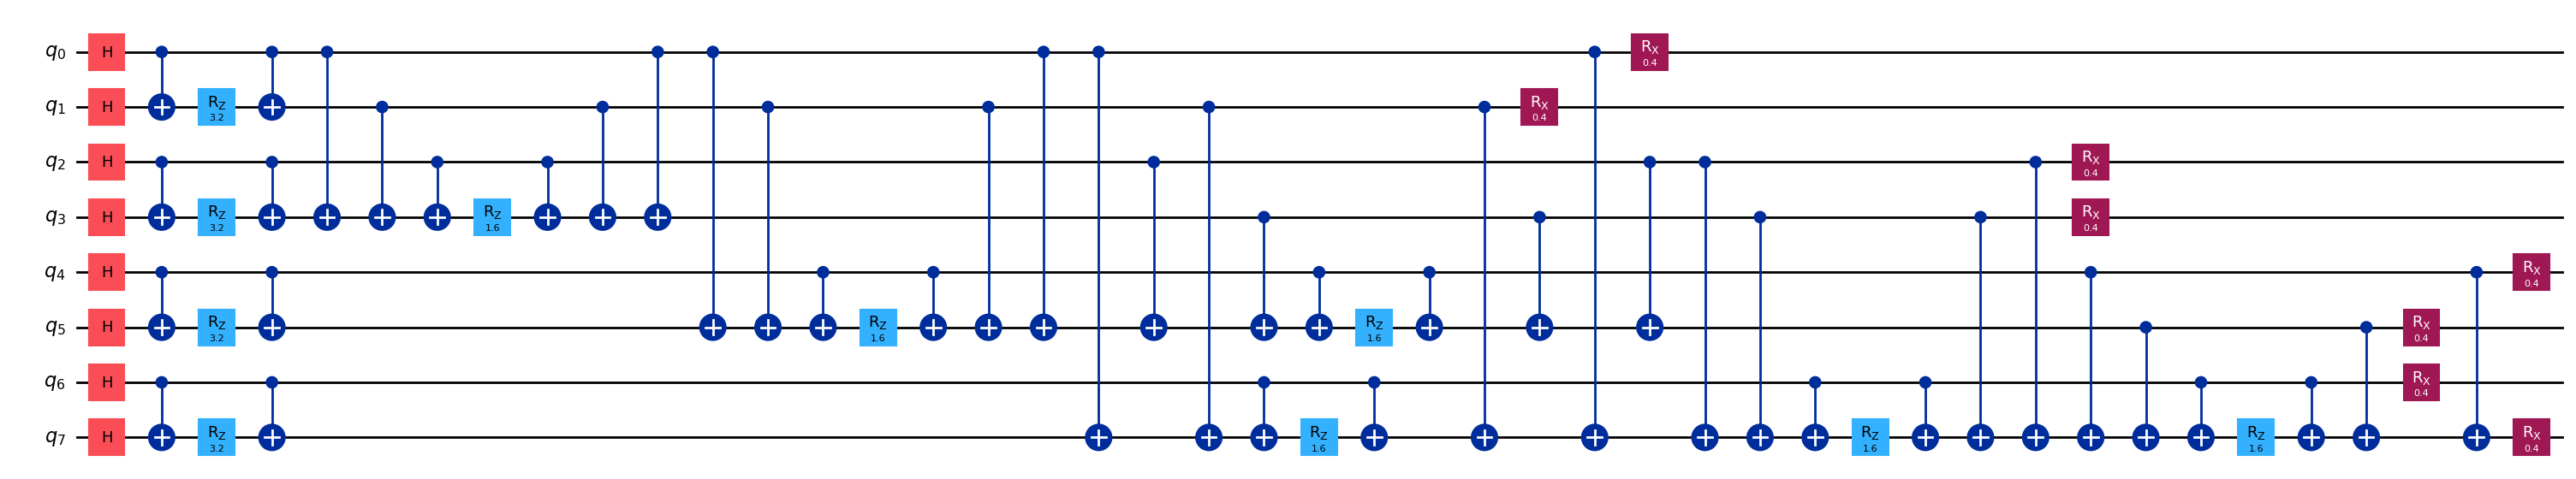

In [14]:
# ============================================
# STEP 4.6: TEST THE QAOA CIRCUIT
# ============================================

gamma_test = 0.1
beta_test = 0.2

test_circuit = build_qaoa_circuit(
    gamma_test,
    beta_test
)

print("Circuit type:", type(test_circuit))

print("Number of qubits:",
      test_circuit.num_qubits)

print("\nCircuit depth:",
      test_circuit.depth())

fig = test_circuit.draw(output='mpl', fold=-1, idle_wires=False)
display(fig)

## **Calculate the Exact QAOA Expected Cost**

Here, we use a `statevector simulator` rather than measurement shots. The statevector  contains the probability amplitudes for all 256 possible bitstrings of the 8 qubits. 

$$\langle H_C \rangle = \bra{\psi(\gamma, \beta)} H_C \ket{\psi(\gamma, \beta)}$$

We will use the `statevector` to calculate the expected cost for a given set of parameters $(\gamma, \beta)$ rather than sampling a limited numbers of measurement. 

In [15]:
# ============================================
# STEP 4.7: EXACT EXPECTED COST
# ============================================

def exact_expected_cost(gamma, beta):

    # Build the QAOA circuit
    qc = build_qaoa_circuit(gamma, beta)

    # Generate the quantum state
    state = Statevector.from_instruction(qc)

    # Calculate probabilities
    probabilities = np.abs(state.data)**2

    expected_cost = 0.0

    # Evaluate all 256 possible configurations
    for index, probability in enumerate(probabilities):

        # Extract the corresponding 8 binary variables
        bits = [(index >> q) & 1 for q in range(8)]

        # Calculate classical cost
        cost = williamson_cost(bits)

        # Add probability-weighted cost
        expected_cost += probability * cost

    return expected_cost


# Test the expected cost
print(
    "Exact expected cost:",
    exact_expected_cost(0.1, 0.2)
)

Exact expected cost: 32.0852125623649


We know that when $\gamma = 0$ and $\beta = 0$, the circuit produces a uniform superposition of all 256 possible configuration. Therefore, its expected cost must equal the average classical cost over all possible configurations. 

In [16]:
# ============================================
# STEP 4.8: VALIDATE QUANTUM AND CLASSICAL COST
# ============================================

classical_average_cost = np.mean([
    williamson_cost(bits)
    for bits in all_configurations
])

quantum_average_cost = exact_expected_cost(0, 0)

print("Classical average cost:",
      classical_average_cost)

print("Quantum average cost:",
      quantum_average_cost)

print("\nDifference:",
      abs(classical_average_cost - quantum_average_cost))

Classical average cost: 32.0
Quantum average cost: 31.999999999999993

Difference: 7.105427357601002e-15


## Optimization of QAOA Parameters
*Understand what we are optimizing*: For QAOA with $p=1$, we have the quantum state as: 
$$\ket{\psi(\gamma, \beta)} = U_M(\beta) U_C(\gamma) \ket{+}^{\otimes 8}$$

The objective is to minimize: 
$$E(\gamma, \beta)= \langle H_C \rangle = \bra{\psi(\gamma, \beta)} H_C \ket{\psi(\gamma, \beta)}$$

We have two parameters $\gamma$ and $\beta$ that controls the cost-unitary and mixer rotations respectly. 

`COBYLA` proposes different values $\gamma$ and $\beta$, evaluates the QAOA expected cost, and attempts to find a minimum.

In [17]:
# ============================================
# STEP 5.2: DEFINE QAOA OPTIMIZATION FUNCTION
# ============================================

def objective_function(parameters):

    gamma = parameters[0]
    beta = parameters[1]

    # Calculate the exact expected cost
    cost = exact_expected_cost(gamma, beta)

    return cost


print("QAOA objective function defined successfully!")

QAOA objective function defined successfully!


For initial experiment, we will search within: 
$$ 0 \leq \gamma \leq\frac{\pi}{4}$$
$$ 0 \leq \beta \leq \pi$$

These are convenient parameter search intervals for this circuit. We are not claiming that they establish a globally optimal solution. 

In [18]:
# ============================================
# STEP 5.3: COBYLA OPTIMIZATION
# ============================================

# Reproducible initial parameters
np.random.seed(42)

initial_gamma = np.random.uniform(0, np.pi/4)
initial_beta = np.random.uniform(0, np.pi)

initial_parameters = [
    initial_gamma,
    initial_beta
]

print("Initial gamma:", initial_gamma)
print("Initial beta:", initial_beta)

print("\nInitial expected cost:",
      objective_function(initial_parameters))


# Run COBYLA
result = minimize(

    objective_function,

    x0=initial_parameters,

    method="COBYLA",

    bounds=[
        (0, np.pi/4),
        (0, np.pi)
    ],

    options={
        "maxiter": 200,
        "rhobeg": 0.1,
        "tol": 0.0001
    }
)


# Extract optimized parameters
optimized_gamma = result.x[0]
optimized_beta = result.x[1]


print("\n========== OPTIMIZATION RESULTS ==========")

print("Optimization message:", result.message)

print("Optimization successful:", result.success)

print("\nOptimized gamma:", optimized_gamma)
print("Optimized beta:", optimized_beta)

print("Optimized expected cost:",
      result.fun)

print("\nFunction evaluations:", result.nfev)

Initial gamma: 0.2941631214613805
Initial beta: 2.9867570806801083

Initial expected cost: 32.00172553505202

========== OPTIMIZATION RESULTS ==========
Optimization message: Optimization terminated successfully.
Optimization successful: True

Optimized gamma: 0.4149104578115891
Optimized beta: 2.9342970193304296
Optimized expected cost: 7.482075956459013

Function evaluations: 124


Optimized QAOA circuit
Number of qubits: 8
Circuit depth: 40


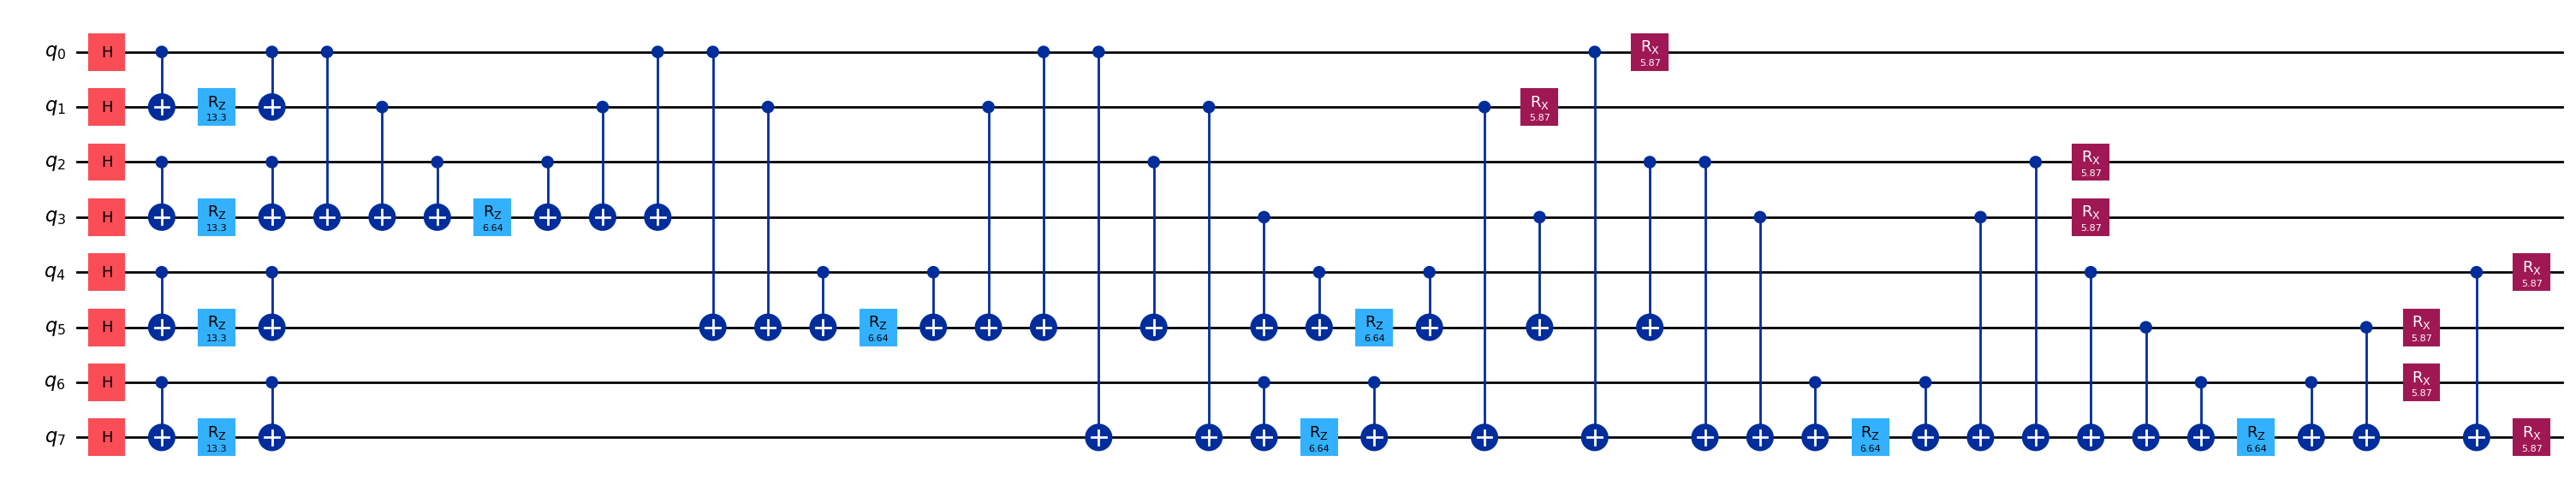

In [19]:
# ============================================
# STEP 5.4: OPTIMIZED QAOA CIRCUIT
# ============================================

from IPython.display import display

optimized_circuit = build_qaoa_circuit(
    optimized_gamma,
    optimized_beta
)

print("Optimized QAOA circuit")
print("Number of qubits:", optimized_circuit.num_qubits)
print("Circuit depth:", optimized_circuit.depth())

# Display using Matplotlib
circuit_figure = optimized_circuit.draw(
    output="mpl",
    fold=-1,
    idle_wires=False
)

display(circuit_figure)

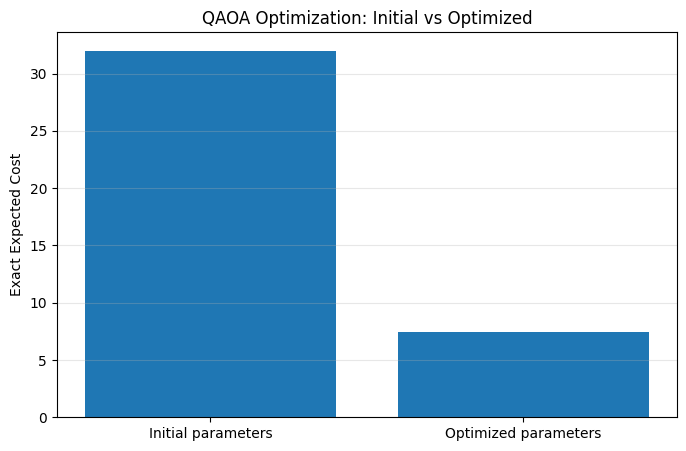

Cost reduction: 24.519649578593004


In [20]:
# ============================================
# STEP 5.5: COMPARE EXPECTED COSTS
# ============================================

initial_cost = objective_function(initial_parameters)
optimized_cost = result.fun

labels = [
    "Initial parameters",
    "Optimized parameters"
]

cost_values = [
    initial_cost,
    optimized_cost
]

plt.figure(figsize=(8, 5))

plt.bar(labels, cost_values)

plt.ylabel("Exact Expected Cost")
plt.title("QAOA Optimization: Initial vs Optimized")

plt.grid(axis="y", alpha=0.3)

plt.show()

print("Cost reduction:",
      initial_cost - optimized_cost)

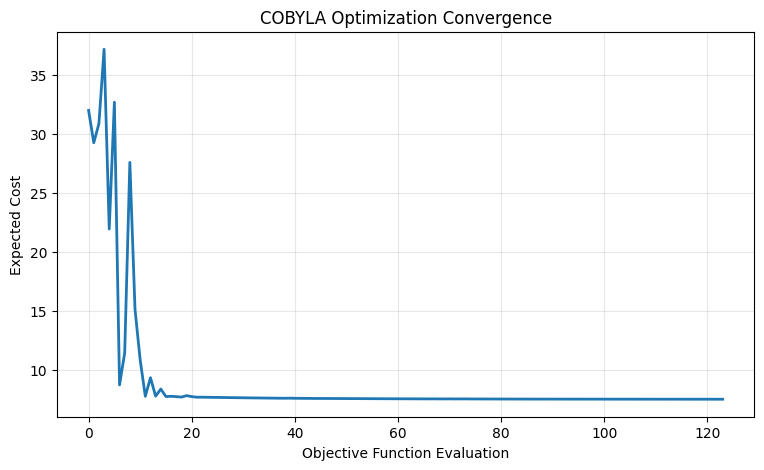

Initial cost: 32.00172553505202
Final cost: 7.482075956459013
Total evaluations: 124


In [21]:
# ============================================
# STEP 5.6: TRACK COBYLA OPTIMIZATION
# ============================================

optimization_history = []

def tracked_objective(parameters):

    cost = exact_expected_cost(
        parameters[0],
        parameters[1]
    )

    optimization_history.append(cost)

    return cost


# Repeat optimization while recording every evaluation

result_tracked = minimize(
    tracked_objective,
    x0=initial_parameters,
    method="COBYLA",
    bounds=[
        (0, np.pi/4),
        (0, np.pi)
    ],
    options={
        "maxiter": 200,
        "rhobeg": 0.1,
        "tol": 0.0001
    }
)


# Plot optimization history

plt.figure(figsize=(9, 5))

plt.plot(
    optimization_history,
    linewidth=2
)

plt.xlabel("Objective Function Evaluation")
plt.ylabel("Expected Cost")

plt.title("COBYLA Optimization Convergence")

plt.grid(alpha=0.3)

plt.show()


print("Initial cost:", optimization_history[0])
print("Final cost:", optimization_history[-1])
print("Total evaluations:", len(optimization_history))

## Calculate the Optimized Quantum-State Probabilities

In [22]:
# Extract the optimized QAOA parameters from COBYLA
optimized_gamma = result.x[0]
optimized_beta = result.x[1]

print("Optimized gamma:", optimized_gamma)
print("Optimized beta:", optimized_beta)

# Build the QAOA circuit using the optimized parameters
qc_optimized = build_qaoa_circuit(
    optimized_gamma,
    optimized_beta
)

# Calculate the exact quantum statevector
state_optimized = Statevector.from_instruction(qc_optimized)

# Calculate the probability of every computational-basis state
probabilities = np.abs(state_optimized.data)**2

print("\nTotal probability:", np.sum(probabilities))
print("Number of possible configurations:", len(probabilities))

Optimized gamma: 0.4149104578115891
Optimized beta: 2.9342970193304296

Total probability: 0.9999999999999989
Number of possible configurations: 256


### Success Probability:

The success probability is 
$$P_{\text{success}} = \sum_{x:C(x) = 0} |\langle x | \psi (\gamma, \beta) |\rangle|^2$$

### Display the Most Probable Quantum States

In [23]:
ranked_configurations = []

for index, probability in enumerate(probabilities):

    bits = tuple((index >> q) & 1 for q in range(8))
    cost = williamson_cost(bits)

    ranked_configurations.append((bits, probability, cost))

# Sort configurations from highest to lowest probability
ranked_configurations.sort(
    key=lambda item: item[1],
    reverse=True
)

print("Top 10 most probable configurations:\n")

for rank, (bits, probability, cost) in enumerate(
    ranked_configurations[:10], start=1
):
    validity = "VALID" if cost == 0 else "INVALID"

    print(
        f"{rank:2d}. Bits = {bits} | "
        f"Probability = {probability:.6f} | "
        f"Cost = {cost:3d} | {validity}"
    )

Top 10 most probable configurations:

 1. Bits = (1, 0, 1, 0, 1, 0, 0, 0) | Probability = 0.009398 | Cost =   0 | VALID
 2. Bits = (0, 1, 1, 0, 1, 0, 0, 0) | Probability = 0.009398 | Cost =   0 | VALID
 3. Bits = (1, 0, 0, 1, 1, 0, 0, 0) | Probability = 0.009398 | Cost =   0 | VALID
 4. Bits = (0, 1, 0, 1, 1, 0, 0, 0) | Probability = 0.009398 | Cost =   0 | VALID
 5. Bits = (1, 0, 1, 0, 0, 1, 0, 0) | Probability = 0.009398 | Cost =   0 | VALID
 6. Bits = (0, 1, 1, 0, 0, 1, 0, 0) | Probability = 0.009398 | Cost =   0 | VALID
 7. Bits = (1, 0, 0, 1, 0, 1, 0, 0) | Probability = 0.009398 | Cost =   0 | VALID
 8. Bits = (0, 1, 0, 1, 0, 1, 0, 0) | Probability = 0.009398 | Cost =   0 | VALID
 9. Bits = (1, 0, 1, 0, 0, 0, 1, 0) | Probability = 0.009398 | Cost =   0 | VALID
10. Bits = (0, 1, 1, 0, 0, 0, 1, 0) | Probability = 0.009398 | Cost =   0 | VALID


## Recosnstruct and Verify the Properties of the 12x12 Hadamard Matrix
It selects the most probable valid configuration from the QAOA output and reconstructs the corresponding 12x12 Williamson-type Hadamard matrix.

In [24]:
# Step 7: Reconstruct a 12x12 Hadamard matrix
valid_configurations_found = [
    (bits, probability)
    for bits, probability, cost in ranked_configurations
    if cost == 0
]
if len(valid_configurations_found) == 0:
    raise ValueError(
        "No valid configuration was identified in Step 6."
    )

# Select the valid configuration with the highest probability
best_bits, best_probability = max(
    valid_configurations_found,
    key=lambda item: item[1]
)

# Convert binary variables into +1 and -1
signs = [binary_to_sign(bit) for bit in best_bits]

# Construct the four symmetric circulant matrices
A = construct_williamson_matrix(*signs[0:2])
B = construct_williamson_matrix(*signs[2:4])
C = construct_williamson_matrix(*signs[4:6])
D = construct_williamson_matrix(*signs[6:8])

# Construct the 12x12 Hadamard matrix
H12 = construct_hadamard(A, B, C, D)

# Verify the Williamson condition
williamson_check = (
    A @ A.T + B @ B.T + C @ C.T + D @ D.T
)

# Verify the Hadamard condition
hadamard_check = H12 @ H12.T

print("Selected QAOA bitstring:", best_bits)
print("Probability:", best_probability)
print("\nWilliamson condition satisfied:",
      np.array_equal(williamson_check, 12 * np.eye(3)))

print("Hadamard condition satisfied:",
      np.array_equal(hadamard_check, 12 * np.eye(12)))

print("\nConstructed Hadamard matrix:")
print(H12)

Selected QAOA bitstring: (1, 0, 1, 0, 1, 0, 0, 0)
Probability: 0.00939849304408225

Williamson condition satisfied: True
Hadamard condition satisfied: True

Constructed Hadamard matrix:
[[-1  1  1 -1  1  1 -1  1  1  1  1  1]
 [ 1 -1  1  1 -1  1  1 -1  1  1  1  1]
 [ 1  1 -1  1  1 -1  1  1 -1  1  1  1]
 [ 1 -1 -1 -1  1  1 -1 -1 -1 -1  1  1]
 [-1  1 -1  1 -1  1 -1 -1 -1  1 -1  1]
 [-1 -1  1  1  1 -1 -1 -1 -1  1  1 -1]
 [ 1 -1 -1  1  1  1 -1  1  1  1 -1 -1]
 [-1  1 -1  1  1  1  1 -1  1 -1  1 -1]
 [-1 -1  1  1  1  1  1  1 -1 -1 -1  1]
 [-1 -1 -1  1 -1 -1 -1  1  1 -1  1  1]
 [-1 -1 -1 -1  1 -1  1 -1  1  1 -1  1]
 [-1 -1 -1 -1 -1  1  1  1 -1  1  1 -1]]


-----
_____

## **Generating Training Data for NN**
Now we want the NN to learn this mapping:
$$\gamma_{\text{initial}}, \beta_{\text{initial}} \rightarrow \gamma_{\text{optimized}}, \beta_{\text{optimized}}$$

we will generate $80$ examples using differnet random initial parameters. Each example is optimized using COBYLA. For speed, we will use a maximum of $120$ iterations per run. we can increase it later. 

In [25]:
import pandas as pd

# Step 8: Generate the NN training dataset

rng = np.random.default_rng(42)

number_of_samples = 80

X_initial = []
Y_optimized = []
dataset_initial_cost = []
dataset_final_cost = []

for i in range(number_of_samples):

    # Generate random initial QAOA parameters
    gamma_start = rng.uniform(0, np.pi / 4)
    beta_start = rng.uniform(0, np.pi)

    initial = [gamma_start, beta_start]

    # Run COBYLA
    opt_result = minimize(
        objective_function,
        x0=initial,
        method="COBYLA",
        bounds=[
            (0, np.pi / 4),
            (0, np.pi)
        ],
        options={
            "maxiter": 120,
            "rhobeg": 0.1,
            "tol": 0.001
        }
    )

    # Store initial parameters and optimized targets
    X_initial.append(initial)
    Y_optimized.append(opt_result.x)

    dataset_initial_cost.append(
        objective_function(initial)
    )

    dataset_final_cost.append(opt_result.fun)

    if (i + 1) % 10 == 0:
        print(f"Completed {i + 1}/{number_of_samples} runs")

# Convert lists into NumPy arrays
X_initial = np.array(X_initial)
Y_optimized = np.array(Y_optimized)

dataset_initial_cost = np.array(dataset_initial_cost)
dataset_final_cost = np.array(dataset_final_cost)

print("\nDataset generation complete.")
print("Input dataset shape:", X_initial.shape)
print("Target dataset shape:", Y_optimized.shape)

print("\nFirst five examples:")
print(pd.DataFrame({
    "gamma_initial": X_initial[:5, 0],
    "beta_initial": X_initial[:5, 1],
    "gamma_optimized": Y_optimized[:5, 0],
    "beta_optimized": Y_optimized[:5, 1],
    "initial_cost": dataset_initial_cost[:5],
    "final_cost": dataset_final_cost[:5]
}))

Completed 10/80 runs
Completed 20/80 runs
Completed 30/80 runs
Completed 40/80 runs
Completed 50/80 runs
Completed 60/80 runs
Completed 70/80 runs
Completed 80/80 runs

Dataset generation complete.
Input dataset shape: (80, 2)
Target dataset shape: (80, 2)

First five examples:
   gamma_initial  beta_initial  gamma_optimized  beta_optimized  initial_cost  \
0       0.607864      1.378777         0.762356        1.741662     73.391615   
1       0.674341      2.190846         0.741037        2.184797     34.010731   
2       0.073967      3.065008         0.174380        2.959757     36.037127   
3       0.597798      2.469494         0.775168        2.068459     35.549717   
4       0.100620      1.414929         0.021411        1.395459     32.218569   

   final_cost  
0    8.101574  
1   27.005576  
2    7.791110  
3   25.098463  
4    8.043128  


### **Now train and evaluate the NN**
We will use a relatively small network: 
$$2 \rightarrow 32 \rightarrow 16 \rightarrow 2$$

The two input neurons represent initial $\gamma$ and $\beta$. The two output neurons predict optimized $\gamma$ and $\beta$.

We normalize the parameters to the interval $[0,1]$. This is important because the two parameters have different numerical ranges:
$$
\gamma\in[0,\pi/4],\qquad
\beta\in[0,\pi].
$$

First, run this cell to split and normalize the data.

In [26]:
# Step 9: Prepare the training and testing data

# Normalize gamma and beta to the range [0, 1]
X_normalized = X_initial.copy()
Y_normalized = Y_optimized.copy()

X_normalized[:, 0] /= (np.pi / 4)
X_normalized[:, 1] /= np.pi

Y_normalized[:, 0] /= (np.pi / 4)
Y_normalized[:, 1] /= np.pi

# Randomly split the dataset: 80% training, 20% testing
torch.manual_seed(42)
indices = torch.randperm(number_of_samples).numpy()

split = int(0.8 * number_of_samples)

train_indices = indices[:split]
test_indices = indices[split:]

X_train = torch.tensor(
    X_normalized[train_indices], dtype=torch.float32
)
Y_train = torch.tensor(
    Y_normalized[train_indices], dtype=torch.float32
)

X_test = torch.tensor(
    X_normalized[test_indices], dtype=torch.float32
)
Y_test = torch.tensor(
    Y_normalized[test_indices], dtype=torch.float32
)

print("Training examples:", len(X_train))
print("Testing examples:", len(X_test))


Training examples: 64
Testing examples: 16


### **Now train the NN**

Epoch    0 | Loss = 0.079129
Epoch  500 | Loss = 0.007643
Epoch 1000 | Loss = 0.007482
Epoch 1500 | Loss = 0.007131
Epoch 2000 | Loss = 0.006932
Epoch 2500 | Loss = 0.006872


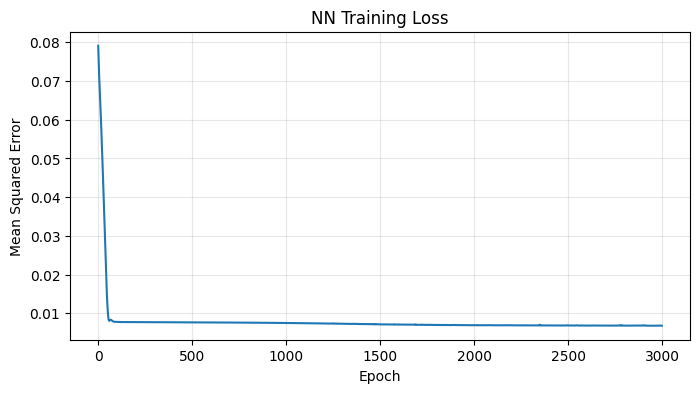

In [27]:
import torch.optim as optim

# Define the neural network: 2 -> 32 -> 16 -> 2

class QAOAParameterNN(nn.Module):

    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(2, 32),
            nn.ReLU(),

            nn.Linear(32, 16),
            nn.ReLU(),

            nn.Linear(16, 2),
            nn.Sigmoid()
        )

    def forward(self, x):
        return self.network(x)


# Initialize the neural network
model = QAOAParameterNN()

# Mean squared error loss
criterion = nn.MSELoss()

# Adam optimizer
optimizer = optim.Adam(
    model.parameters(),
    lr=0.005
)

# Train the network
epochs = 3000
training_losses = []

for epoch in range(epochs):

    model.train()

    predictions = model(X_train)
    loss = criterion(predictions, Y_train)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    training_losses.append(loss.item())

    if epoch % 500 == 0:
        print(f"Epoch {epoch:4d} | Loss = {loss.item():.6f}")


# Plot training loss
plt.figure(figsize=(8, 4))
plt.plot(training_losses)
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.title("NN Training Loss")
plt.grid(alpha=0.3)
plt.show()


Finally, we test whether the NN's predicted parameters actually produce a low QAOA cost. This is more important than looking at the neural network's prediction error alone.

In [28]:
# Evaluate the trained neural network on unseen initial parameters

model.eval()

with torch.no_grad():
    predictions_normalized = model(X_test).numpy()

# Convert normalized predictions back to physical parameter ranges
predicted_parameters = predictions_normalized.copy()

predicted_parameters[:, 0] *= (np.pi / 4)
predicted_parameters[:, 1] *= np.pi

# Recover the original test initial parameters
test_initial_parameters = X_initial[test_indices]

# Calculate actual QAOA costs
initial_test_costs = []
nn_test_costs = []

for i in range(len(test_indices)):

    gamma_start, beta_start = test_initial_parameters[i]
    gamma_nn, beta_nn = predicted_parameters[i]

    initial_test_costs.append(
        exact_expected_cost(gamma_start, beta_start)
    )

    nn_test_costs.append(
        exact_expected_cost(gamma_nn, beta_nn)
    )

# COBYLA reference costs for the same test examples
cobyla_test_costs = dataset_final_cost[test_indices]

print("Mean cost comparison on unseen test examples:")
print("-----------------------------------------------")
print("Initial QAOA cost:",
      np.mean(initial_test_costs))

print("NN-predicted QAOA cost:",
      np.mean(nn_test_costs))

print("COBYLA-optimized cost:",
      np.mean(cobyla_test_costs))


Mean cost comparison on unseen test examples:
-----------------------------------------------
Initial QAOA cost: 37.883555870943425
NN-predicted QAOA cost: 52.13273702306626
COBYLA-optimized cost: 16.29533176065384


Table between the NN-predicted parameters and the COBYLA-optimized parameters.

|Result| Meaning |
|------|---------|
| Initial QAOA Cost | Performance before optimization |
| NN-predicted Cost | Performance using NN-predicted parameters direcly |
| COBYLA-optimized Cost | Reference performance after numerical optimization using COBYLA |

In [29]:
success_probability = 0.0
valid_configurations_found = []

for index, probability in enumerate(probabilities):

    # Convert the statevector index into 8 binary variables
    bits = tuple((index >> q) & 1 for q in range(8))

    # Evaluate the Williamson cost
    cost = williamson_cost(bits)

    # A zero cost means a valid Williamson configuration
    if cost == 0:
        success_probability += probability
        valid_configurations_found.append((bits, probability))

print("Number of valid configurations:", len(valid_configurations_found))

print("\nQAOA Success Probability:")
print(success_probability)

print("\nQAOA Success Probability (%):")
print(success_probability * 100)

print("\nUniform baseline success probability: 25%")


Number of valid configurations: 64

QAOA Success Probability:
0.6015035548212638

QAOA Success Probability (%):
60.150355482126386

Uniform baseline success probability: 25%


### NN-Assisted COBYLA Experiment

In [30]:
# STEP 10: Compare standard COBYLA with NN-assisted COBYLA

# Parameter bounds
parameter_bounds = [
    (0, np.pi / 4),
    (0, np.pi)
]

# Store results for all test examples
comparison_results = []

for i in range(len(X_test)):

    # Original initial parameters
    original_parameters = test_initial_parameters[i]

    # Neural network prediction
    nn_parameters = predicted_parameters[i]

    # -----------------------------------------
    # Method 1: Initial QAOA cost
    # -----------------------------------------

    initial_cost = exact_expected_cost(
        original_parameters[0],
        original_parameters[1]
    )

    # -----------------------------------------
    # Method 2: NN-only prediction
    # -----------------------------------------

    nn_cost = exact_expected_cost(
        nn_parameters[0],
        nn_parameters[1]
    )

    # -----------------------------------------
    # Method 3: Standard COBYLA
    # -----------------------------------------

    standard_result = minimize(
        objective_function,
        x0=original_parameters,
        method="COBYLA",
        bounds=parameter_bounds,
        options={
            "maxiter": 200,
            "rhobeg": 0.1,
            "tol": 0.0001
        }
    )

    # -----------------------------------------
    # Method 4: NN-assisted COBYLA
    # -----------------------------------------

    hybrid_result = minimize(
        objective_function,
        x0=nn_parameters,
        method="COBYLA",
        bounds=parameter_bounds,
        options={
            "maxiter": 200,
            "rhobeg": 0.1,
            "tol": 0.0001
        }
    )

    # Save all results
    comparison_results.append({
        "Initial Cost": initial_cost,
        "NN Cost": nn_cost,
        "Standard COBYLA Cost": standard_result.fun,
        "NN + COBYLA Cost": hybrid_result.fun,
        "Standard Evaluations": standard_result.nfev,
        "Hybrid Evaluations": hybrid_result.nfev
    })

# Convert results to a DataFrame
comparison_df = pd.DataFrame(comparison_results)

print("Comparison on the 16 unseen test examples:\n")
print(comparison_df.round(4).to_string(index=False))

print("\nMEAN PERFORMANCE")
print("------------------------------")

print(
    comparison_df.mean(numeric_only=True).round(4)
)

Comparison on the 16 unseen test examples:

 Initial Cost  NN Cost  Standard COBYLA Cost  NN + COBYLA Cost  Standard Evaluations  Hybrid Evaluations
      36.1520  27.5372               31.5316            7.4962                    27                 200
      34.1553  48.5122                7.4871            7.4851                   200                  84
      32.7510  50.7367                7.4997            7.5004                   200                 100
      29.8758  55.1946               26.5964           26.5963                   139                 121
      23.1129  32.3067                7.4967            7.4828                   169                  83
      32.2016  34.2208               31.5317           31.5318                    37                  36
      36.0371  59.5461                7.4960            7.4838                   200                 193
      51.4315  47.2428                7.4870            7.4881                   153                 146
      44.64

## Quantify the Improvements
Before changing the neural network,I want to run one additional analysis. I should calculate the paired improvement for every test example and visualize the results.

In [31]:
# STEP 11: Detailed comparison of standard and hybrid optimization

analysis_df = comparison_df.copy()

# Positive improvement means NN + COBYLA performed better
analysis_df["Cost Improvement"] = (
    analysis_df["Standard COBYLA Cost"]
    - analysis_df["NN + COBYLA Cost"]
)

analysis_df["Improvement Percentage"] = (
    analysis_df["Cost Improvement"]
    / analysis_df["Standard COBYLA Cost"]
) * 100

# Calculate overall statistics
standard_mean = analysis_df["Standard COBYLA Cost"].mean()
hybrid_mean = analysis_df["NN + COBYLA Cost"].mean()

standard_evals = analysis_df["Standard Evaluations"].mean()
hybrid_evals = analysis_df["Hybrid Evaluations"].mean()

print("DETAILED PERFORMANCE ANALYSIS")
print("--------------------------------------")

print("Standard COBYLA mean cost:", standard_mean)
print("NN + COBYLA mean cost:", hybrid_mean)

print(
    "Mean cost improvement (%):",
    (standard_mean - hybrid_mean) / standard_mean * 100
)

print("\nMean objective evaluations:")
print("Standard COBYLA:", standard_evals)
print("NN + COBYLA:", hybrid_evals)

print("\nNumber of cases where hybrid performed better:",
      (analysis_df["Cost Improvement"] > 0).sum())

print("Number of cases where standard performed better:",
      (analysis_df["Cost Improvement"] < 0).sum())

print("\nDetailed paired results:")
print(
    analysis_df[
        [
            "Standard COBYLA Cost",
            "NN + COBYLA Cost",
            "Cost Improvement",
            "Improvement Percentage"
        ]
    ].round(4).to_string(index=True)
)


DETAILED PERFORMANCE ANALYSIS
--------------------------------------
Standard COBYLA mean cost: 15.94903722475106
NN + COBYLA mean cost: 13.092807580002386
Mean cost improvement (%): 17.90847688483751

Mean objective evaluations:
Standard COBYLA: 134.5625
NN + COBYLA: 136.6875

Number of cases where hybrid performed better: 8
Number of cases where standard performed better: 8

Detailed paired results:
    Standard COBYLA Cost  NN + COBYLA Cost  Cost Improvement  Improvement Percentage
0                31.5316            7.4962           24.0354                 76.2263
1                 7.4871            7.4851            0.0020                  0.0266
2                 7.4997            7.5004           -0.0007                 -0.0098
3                26.5964           26.5963            0.0000                  0.0001
4                 7.4967            7.4828            0.0140                  0.1861
5                31.5317           31.5318           -0.0001                 -0.0002


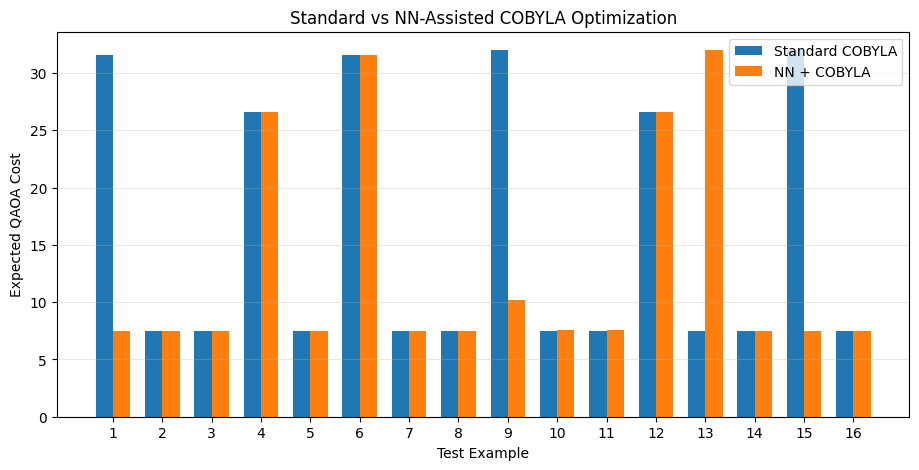

In [32]:
# Visualize the cost comparison for all 16 test examples

x = np.arange(len(analysis_df))
width = 0.35

plt.figure(figsize=(11, 5))

plt.bar(
    x - width/2,
    analysis_df["Standard COBYLA Cost"],
    width,
    label="Standard COBYLA"
)

plt.bar(
    x + width/2,
    analysis_df["NN + COBYLA Cost"],
    width,
    label="NN + COBYLA"
)

plt.xlabel("Test Example")
plt.ylabel("Expected QAOA Cost")
plt.title("Standard vs NN-Assisted COBYLA Optimization")
plt.xticks(x, [f"{i+1}" for i in x])
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.show()
